<a href="https://colab.research.google.com/github/shubhranshu-bit/AIML-research-papers/blob/main/Ensemble_Stacking_LG.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

## Mounting with Drive

In [ ]:
from google.colab import drive

# Mount Google Drive
drive.mount('/content/drive')


from google.colab import drive
drive.mount('/content/drive')

file_path = '/content/drive/MyDrive/Fault_dataset'

Mounted at /content/drive
Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


# LG fault

In [ ]:
import pandas as pd
path='/content/drive/MyDrive/Fault_dataset/AG modified.csv'
df = pd.read_csv(path)
df

,Time,Absolute Ia,Absolute Ib,Absolute Ic,Fault
0,0.000000,0.049527,0.190896,0.130947,0
1,0.000167,0.055313,0.187909,0.123746,0
2,0.000333,0.060952,0.184199,0.116002,0
3,0.000500,0.066418,0.179768,0.107739,0
4,0.000667,0.071680,0.174620,0.098983,0
...,...,...,...,...,...
5995,0.999127,0.135601,0.060845,0.179685,0
5996,0.999293,0.133126,0.067954,0.185650,0
5997,0.999460,0.130064,0.074860,0.190887,0
5998,0.999627,0.126422,0.081527,0.195361,0


In [ ]:
y = df['Fault']
y

0       0
1       0
2       0
3       0
4       0
       ..
5995    0
5996    0
5997    0
5998    0
5999    0
Name: Fault, Length: 6000, dtype: int64

In [ ]:
X = df.drop(['Time', 'Fault'], axis=1)
X

,Absolute Ia,Absolute Ib,Absolute Ic
0,0.049527,0.190896,0.130947
1,0.055313,0.187909,0.123746
2,0.060952,0.184199,0.116002
3,0.066418,0.179768,0.107739
4,0.071680,0.174620,0.098983
...,...,...,...
5995,0.135601,0.060845,0.179685
5996,0.133126,0.067954,0.185650
5997,0.130064,0.074860,0.190887
5998,0.126422,0.081527,0.195361


In [ ]:
import numpy as np
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.svm import SVC
from sklearn.neural_network import MLPClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report, precision_score


In [ ]:
X_lg_train, X_lg_test, y_lg_train, y_lg_test = train_test_split(X, y, test_size=0.2, random_state=42)


In [ ]:
dt_lg_classifier = DecisionTreeClassifier(max_depth=5,random_state=42)
nb_lg_classifier = GaussianNB()
svm_lg_classifier = SVC(kernel='linear', random_state=42)
mlp_lg_classifier = MLPClassifier(alpha=1, max_iter=1000)
rf_lg_classifier = RandomForestClassifier(n_estimators=100, random_state=42)


dt_lg_classifier.fit(X_lg_train, y_lg_train)
nb_lg_classifier.fit(X_lg_train, y_lg_train)
svm_lg_classifier.fit(X_lg_train, y_lg_train)
mlp_lg_classifier.fit(X_lg_train, y_lg_train)
rf_lg_classifier.fit(X_lg_train, y_lg_train)

dt_lg_pred = dt_lg_classifier.predict(X_lg_test)
nb_lg_pred = nb_lg_classifier.predict(X_lg_test)
svm_lg_pred = svm_lg_classifier.predict(X_lg_test)
mlp_lg_pred = mlp_lg_classifier.predict(X_lg_test)
rf_lg_pred = rf_lg_classifier.predict(X_lg_test)

# Calculate individual accuracies

dt_lg_accuracy = accuracy_score(y_lg_test, dt_lg_pred)
nb_lg_accuracy = accuracy_score(y_lg_test, nb_lg_pred)
svm_lg_accuracy = accuracy_score(y_lg_test, svm_lg_pred)
mlp_lg_accuracy = accuracy_score(y_lg_test, mlp_lg_pred)
rf_lg_accuracy = accuracy_score(y_lg_test, rf_lg_pred)

print("Decision Tree Accuracy:", dt_lg_accuracy)
print("Naive Bayes Accuracy:", nb_lg_accuracy)
print("SVM Accuracy:", svm_lg_accuracy)
print("MLP Accuracy:", mlp_lg_accuracy)
print("Random Forest Accuracy:", rf_lg_accuracy)

Decision Tree Accuracy: 0.9525
Naive Bayes Accuracy: 0.9333333333333333
SVM Accuracy: 0.9141666666666667
MLP Accuracy: 0.915
Random Forest Accuracy: 0.9591666666666666


In [ ]:
from sklearn.ensemble import StackingClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.svm import SVC
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import accuracy_score, f1_score

# Initialize base classifiers
base_estimators = [
    ('rf', RandomForestClassifier(n_estimators=100, random_state=42)),
    ('dt', DecisionTreeClassifier(random_state=42)),
    ('nb', GaussianNB()),
    ('svm', SVC(kernel='linear', probability=True, random_state=42)),
    ('mlp', MLPClassifier(alpha=1, max_iter=1000))
]

# Train base classifiers
for name, classifier in base_estimators:
    classifier.fit(X_lg_train, y_lg_train)

# Generate predictions from base classifiers using training data
dt_pred_train = base_estimators[1][1].predict(X_lg_train)
nb_pred_train = base_estimators[2][1].predict(X_lg_train)
svm_pred_train = base_estimators[3][1].predict(X_lg_train)
rf_pred_train = base_estimators[0][1].predict(X_lg_train)
mlp_pred_train = base_estimators[4][1].predict(X_lg_train)

# Prepare features matrix for meta-model (stacking)
X_train_stacked = np.column_stack((dt_pred_train, nb_pred_train, svm_pred_train, rf_pred_train, mlp_pred_train))

# Initialize meta-model (stacking estimator)
final_estimator = final_estimator = KNeighborsClassifier(n_neighbors=5)

# Initialize stacking classifier
stacking_classifier = StackingClassifier(
    estimators=base_estimators,
    final_estimator=final_estimator,
    cv=20  # Number of folds for cross-validation during training
)

# Train stacking ensemble model
stacking_classifier.fit(X_lg_train, y_lg_train)

# Generate predictions from stacking ensemble model using test data
stacking_pred = stacking_classifier.predict(X_lg_test)
y_train_pred = stacking_classifier.predict(X_lg_train)

# Evaluate stacking ensemble model
ensemble_lg_accuracy = accuracy_score(y_lg_test, stacking_pred)
print("Stacking Ensemble Accuracy:", ensemble_lg_accuracy)



# Training set model performance
stack_model_train_accuracy = accuracy_score(y_lg_train, y_train_pred) # Calculate Accuracy
stack_model_train_f1 = f1_score(y_lg_train, y_train_pred, average='weighted') # Calculate F1-score

# Test set model performance
stack_model_test_accuracy = accuracy_score(y_lg_test, stacking_pred) # Calculate Accuracy
stack_model_test_f1 = f1_score(y_lg_test, stacking_pred, average='weighted') # Calculate F1-score

print('Model performance for Training set')
print('- Accuracy: %s' % stack_model_train_accuracy)
print('- F1 score: %s' % stack_model_train_f1)
print('----------------------------------')
print('Model performance for Test set')
print('- Accuracy: %s' % stack_model_test_accuracy)
print('- F1 score: %s' % stack_model_test_f1)

Stacking Ensemble Accuracy: 0.9633333333333334
Model performance for Training set
- Accuracy: 0.9891666666666666
- F1 score: 0.9890562141794319
----------------------------------
Model performance for Test set
- Accuracy: 0.9633333333333334
- F1 score: 0.9621496671572991


In [ ]:
from sklearn.metrics import confusion_matrix
import seaborn as sns
import matplotlib.pyplot as plt

cm = confusion_matrix(y_lg_test, stacking_pred)
cm

array([[952,   3],
       [ 41, 204]])

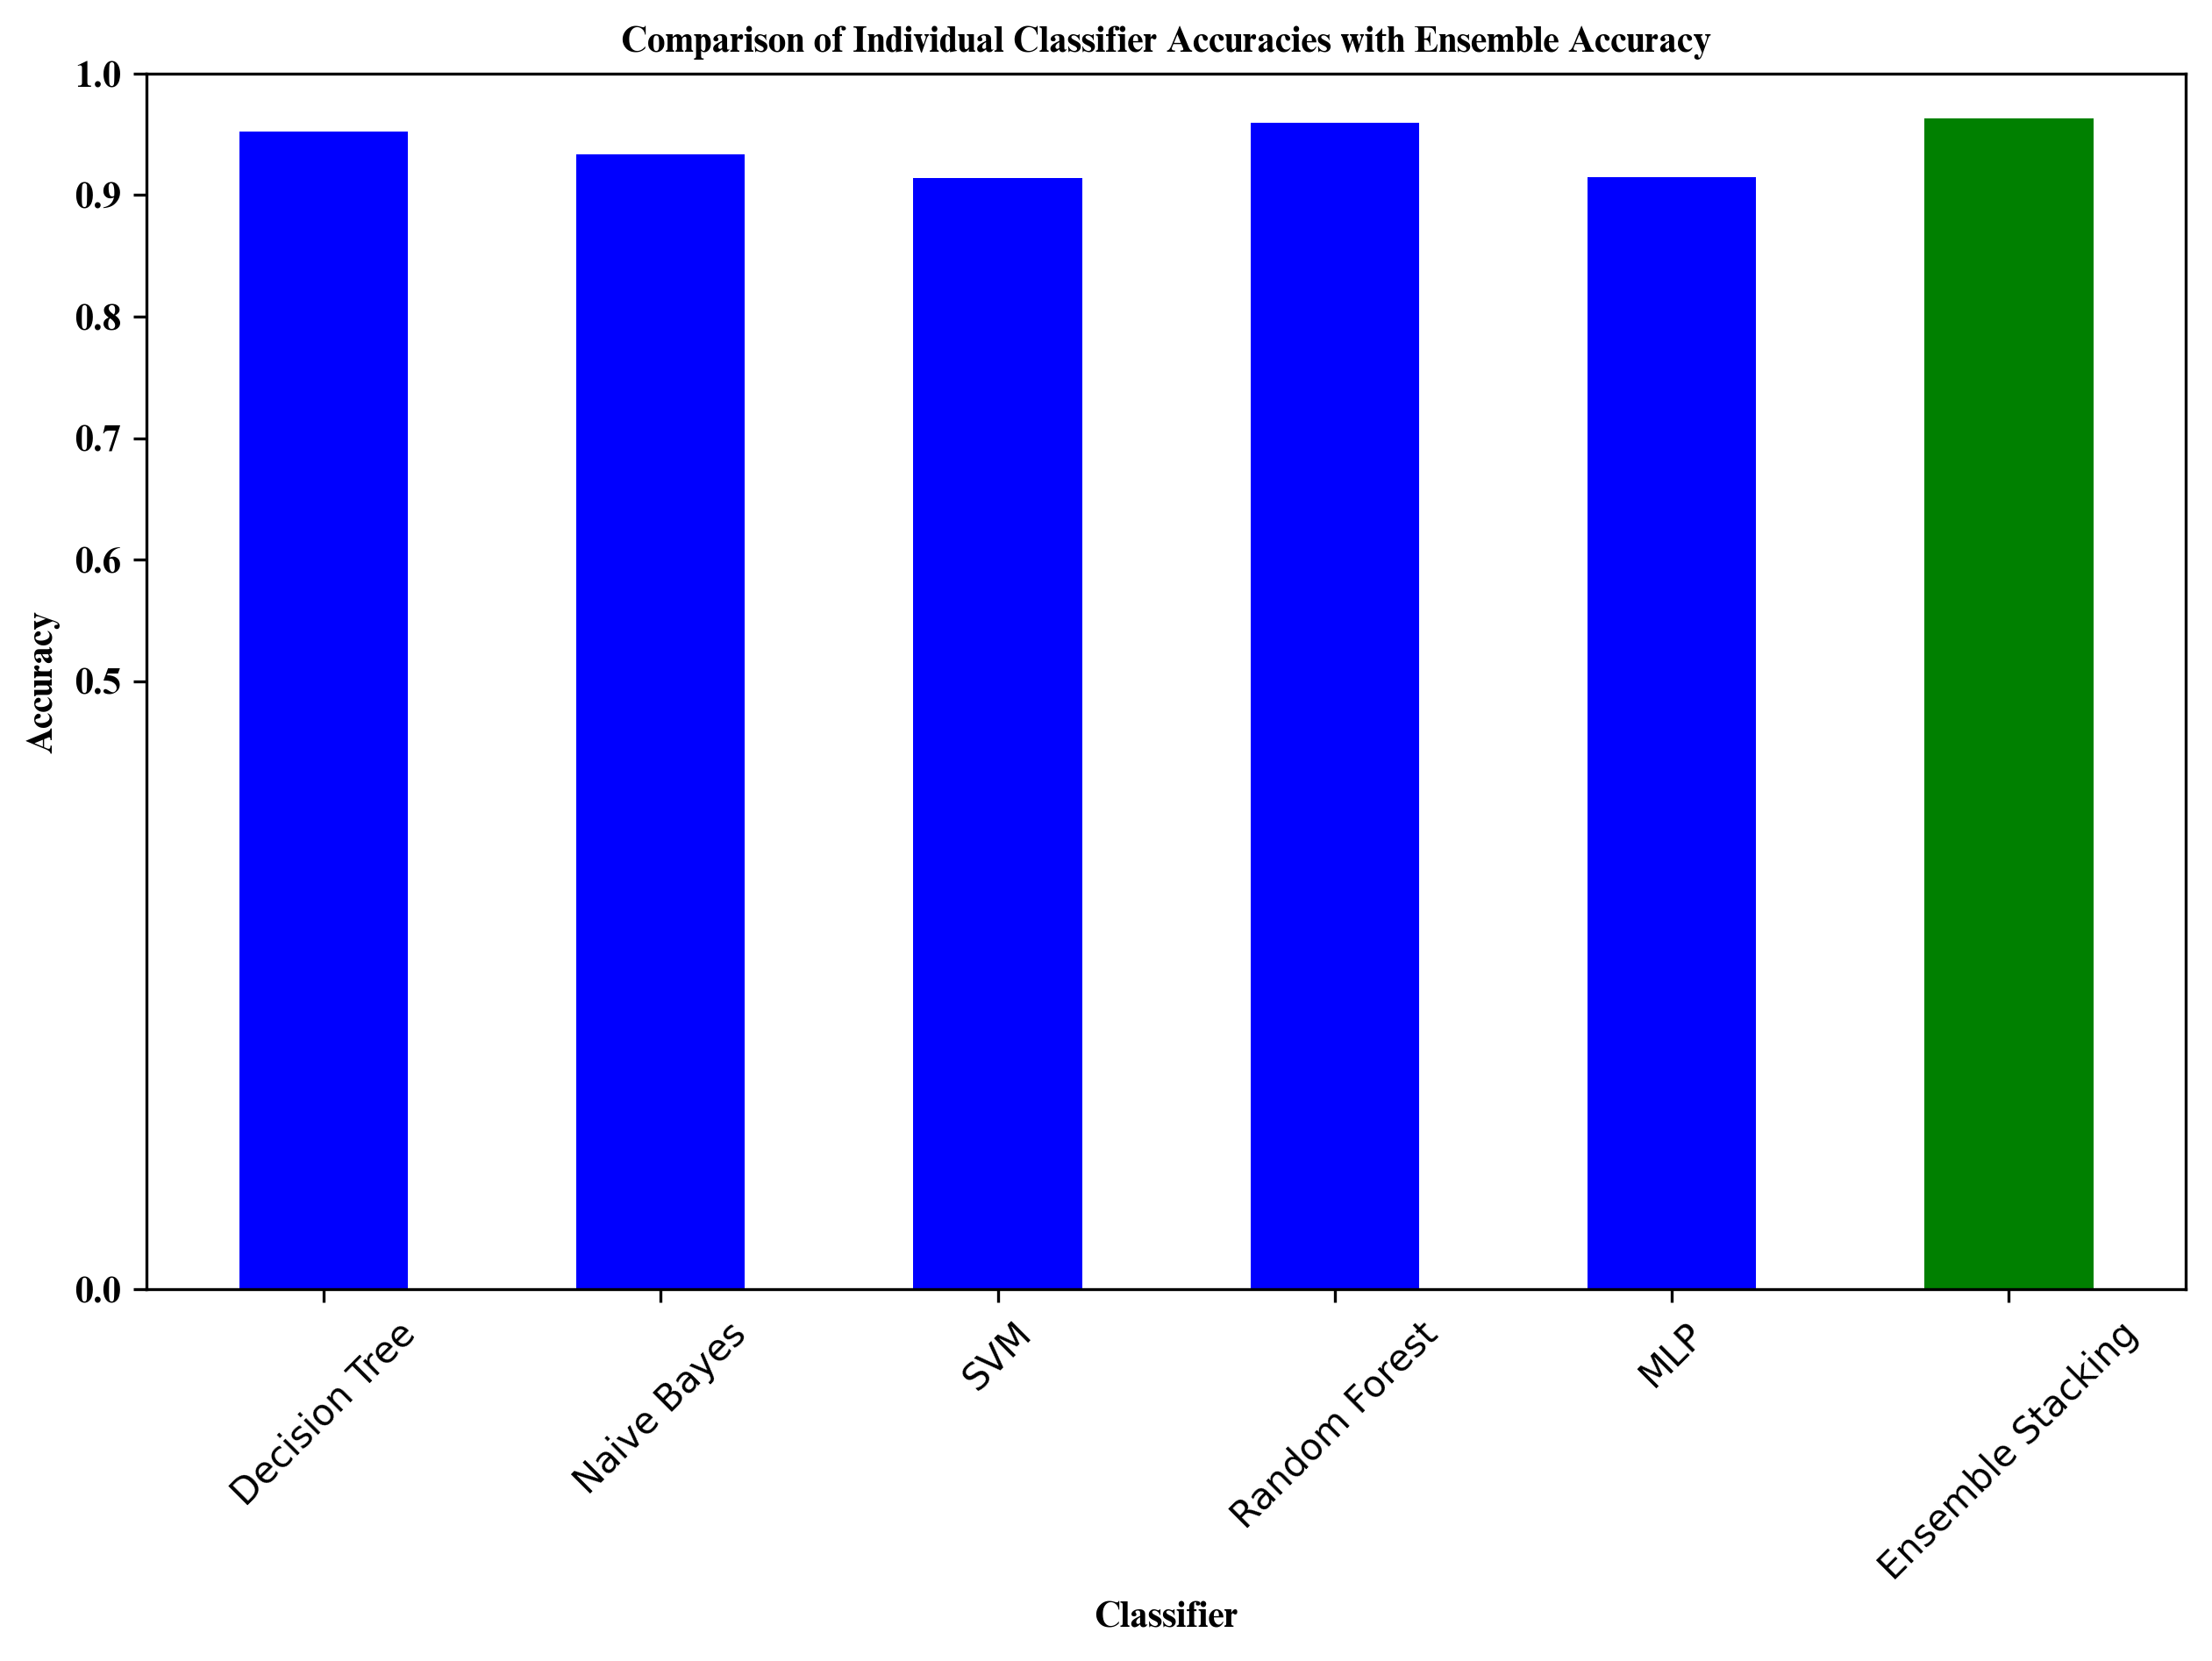

In [ ]:
import matplotlib.pyplot as plt
from matplotlib.font_manager import FontProperties
font_path = '/content/drive/MyDrive/Fault_dataset/times new roman bold.ttf'
custom_font = FontProperties(fname=font_path)

# Plotting individual accuracies vs ensemble accuracy
labels = ['Decision Tree', 'Naive Bayes', 'SVM', 'Random Forest', 'MLP', 'Ensemble Stacking']
accuracies = [dt_lg_accuracy, nb_lg_accuracy, svm_lg_accuracy, rf_lg_accuracy, mlp_lg_accuracy, stack_model_test_accuracy]


plt.figure(figsize=(10, 6), dpi=300)
bar_width = 0.5  # Adjust the width of bars
bar_positions = range(len(labels))

plt.bar(bar_positions, accuracies, color=['b', 'b', 'b', 'b', 'b', 'g'], width=bar_width)
plt.xlabel('Classifier', fontproperties=custom_font)
plt.ylabel('Accuracy', fontproperties=custom_font)
plt.title('Comparison of Individual Classifier Accuracies with Ensemble Accuracy', fontproperties=custom_font)
plt.xticks(bar_positions, labels, rotation=45)  # Rotate labels for better readability
plt.yticks([0, 0.5, 0.6, 0.7, 0.8, 0.9, 1.0], fontproperties=custom_font)  # Adjust y-axis ticks spacing
plt.ylim(0, 1)  # Set y-axis limit to ensure proper visualization
plt.savefig('plot.png', dpi=300)
plt.show()


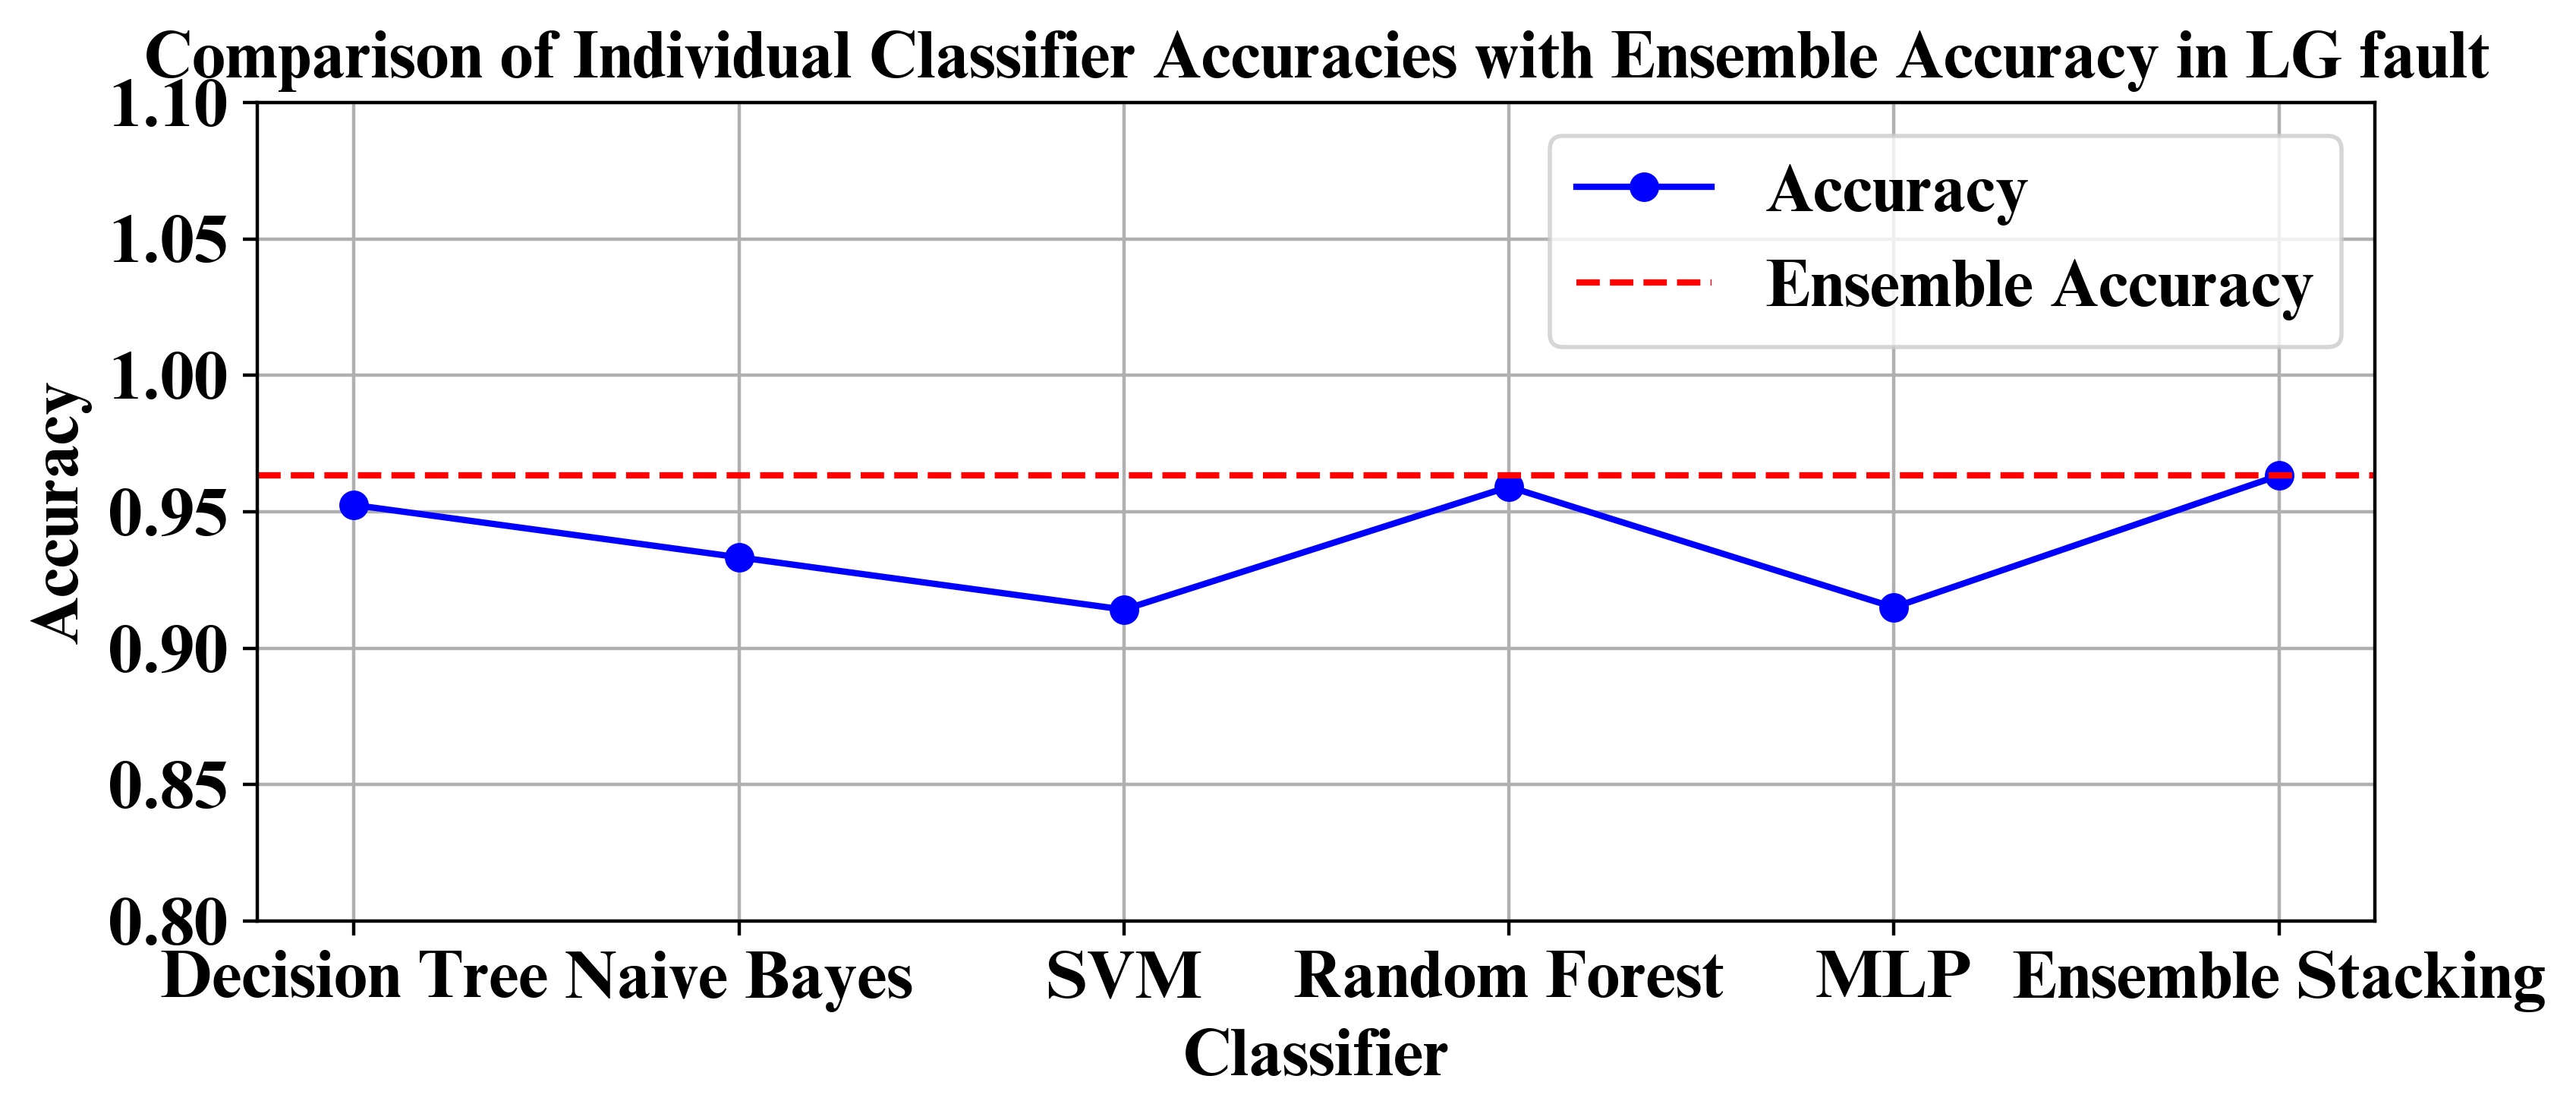

In [ ]:
import matplotlib.pyplot as plt
from matplotlib.font_manager import FontProperties

font_path = '/content/drive/MyDrive/Fault_dataset/times new roman bold.ttf'
custom_font = FontProperties(fname=font_path)
custom_font.set_size(16)

plt.figure(figsize=(9, 3.5), dpi=400)
plt.plot(labels, accuracies, marker='o', color='b', label='Accuracy')
plt.axhline(y=stack_model_test_accuracy, color='r', linestyle='--', label='Ensemble Accuracy')

# Setting font properties for title, axis labels, and legend
plt.xlabel('Classifier', fontproperties=custom_font)
plt.ylabel('Accuracy', fontproperties=custom_font)
plt.title('Comparison of Individual Classifier Accuracies with Ensemble Accuracy in LG fault', fontproperties=custom_font)

# Getting current axes and setting font properties for both x and y ticks
ax = plt.gca()
ax.tick_params(axis='x', labelsize=10)  # Adjust font size as needed
ax.tick_params(axis='y', labelsize=10)  # Adjust font size as needed
for label in ax.get_xticklabels() + ax.get_yticklabels():
    label.set_fontproperties(custom_font)

# Setting font properties for legend
plt.legend(prop=custom_font)
plt.xticks(fontproperties=custom_font, fontsize=16)
plt.yticks(fontproperties=custom_font, fontsize=16)
plt.ylim(0.8, 1.1)  # Set y-axis limit to ensure proper visualization
plt.grid(True)

# Saving the plot with custom font
plt.savefig('plot.png', dpi=400, bbox_inches='tight', pad_inches=0.1)
plt.show()


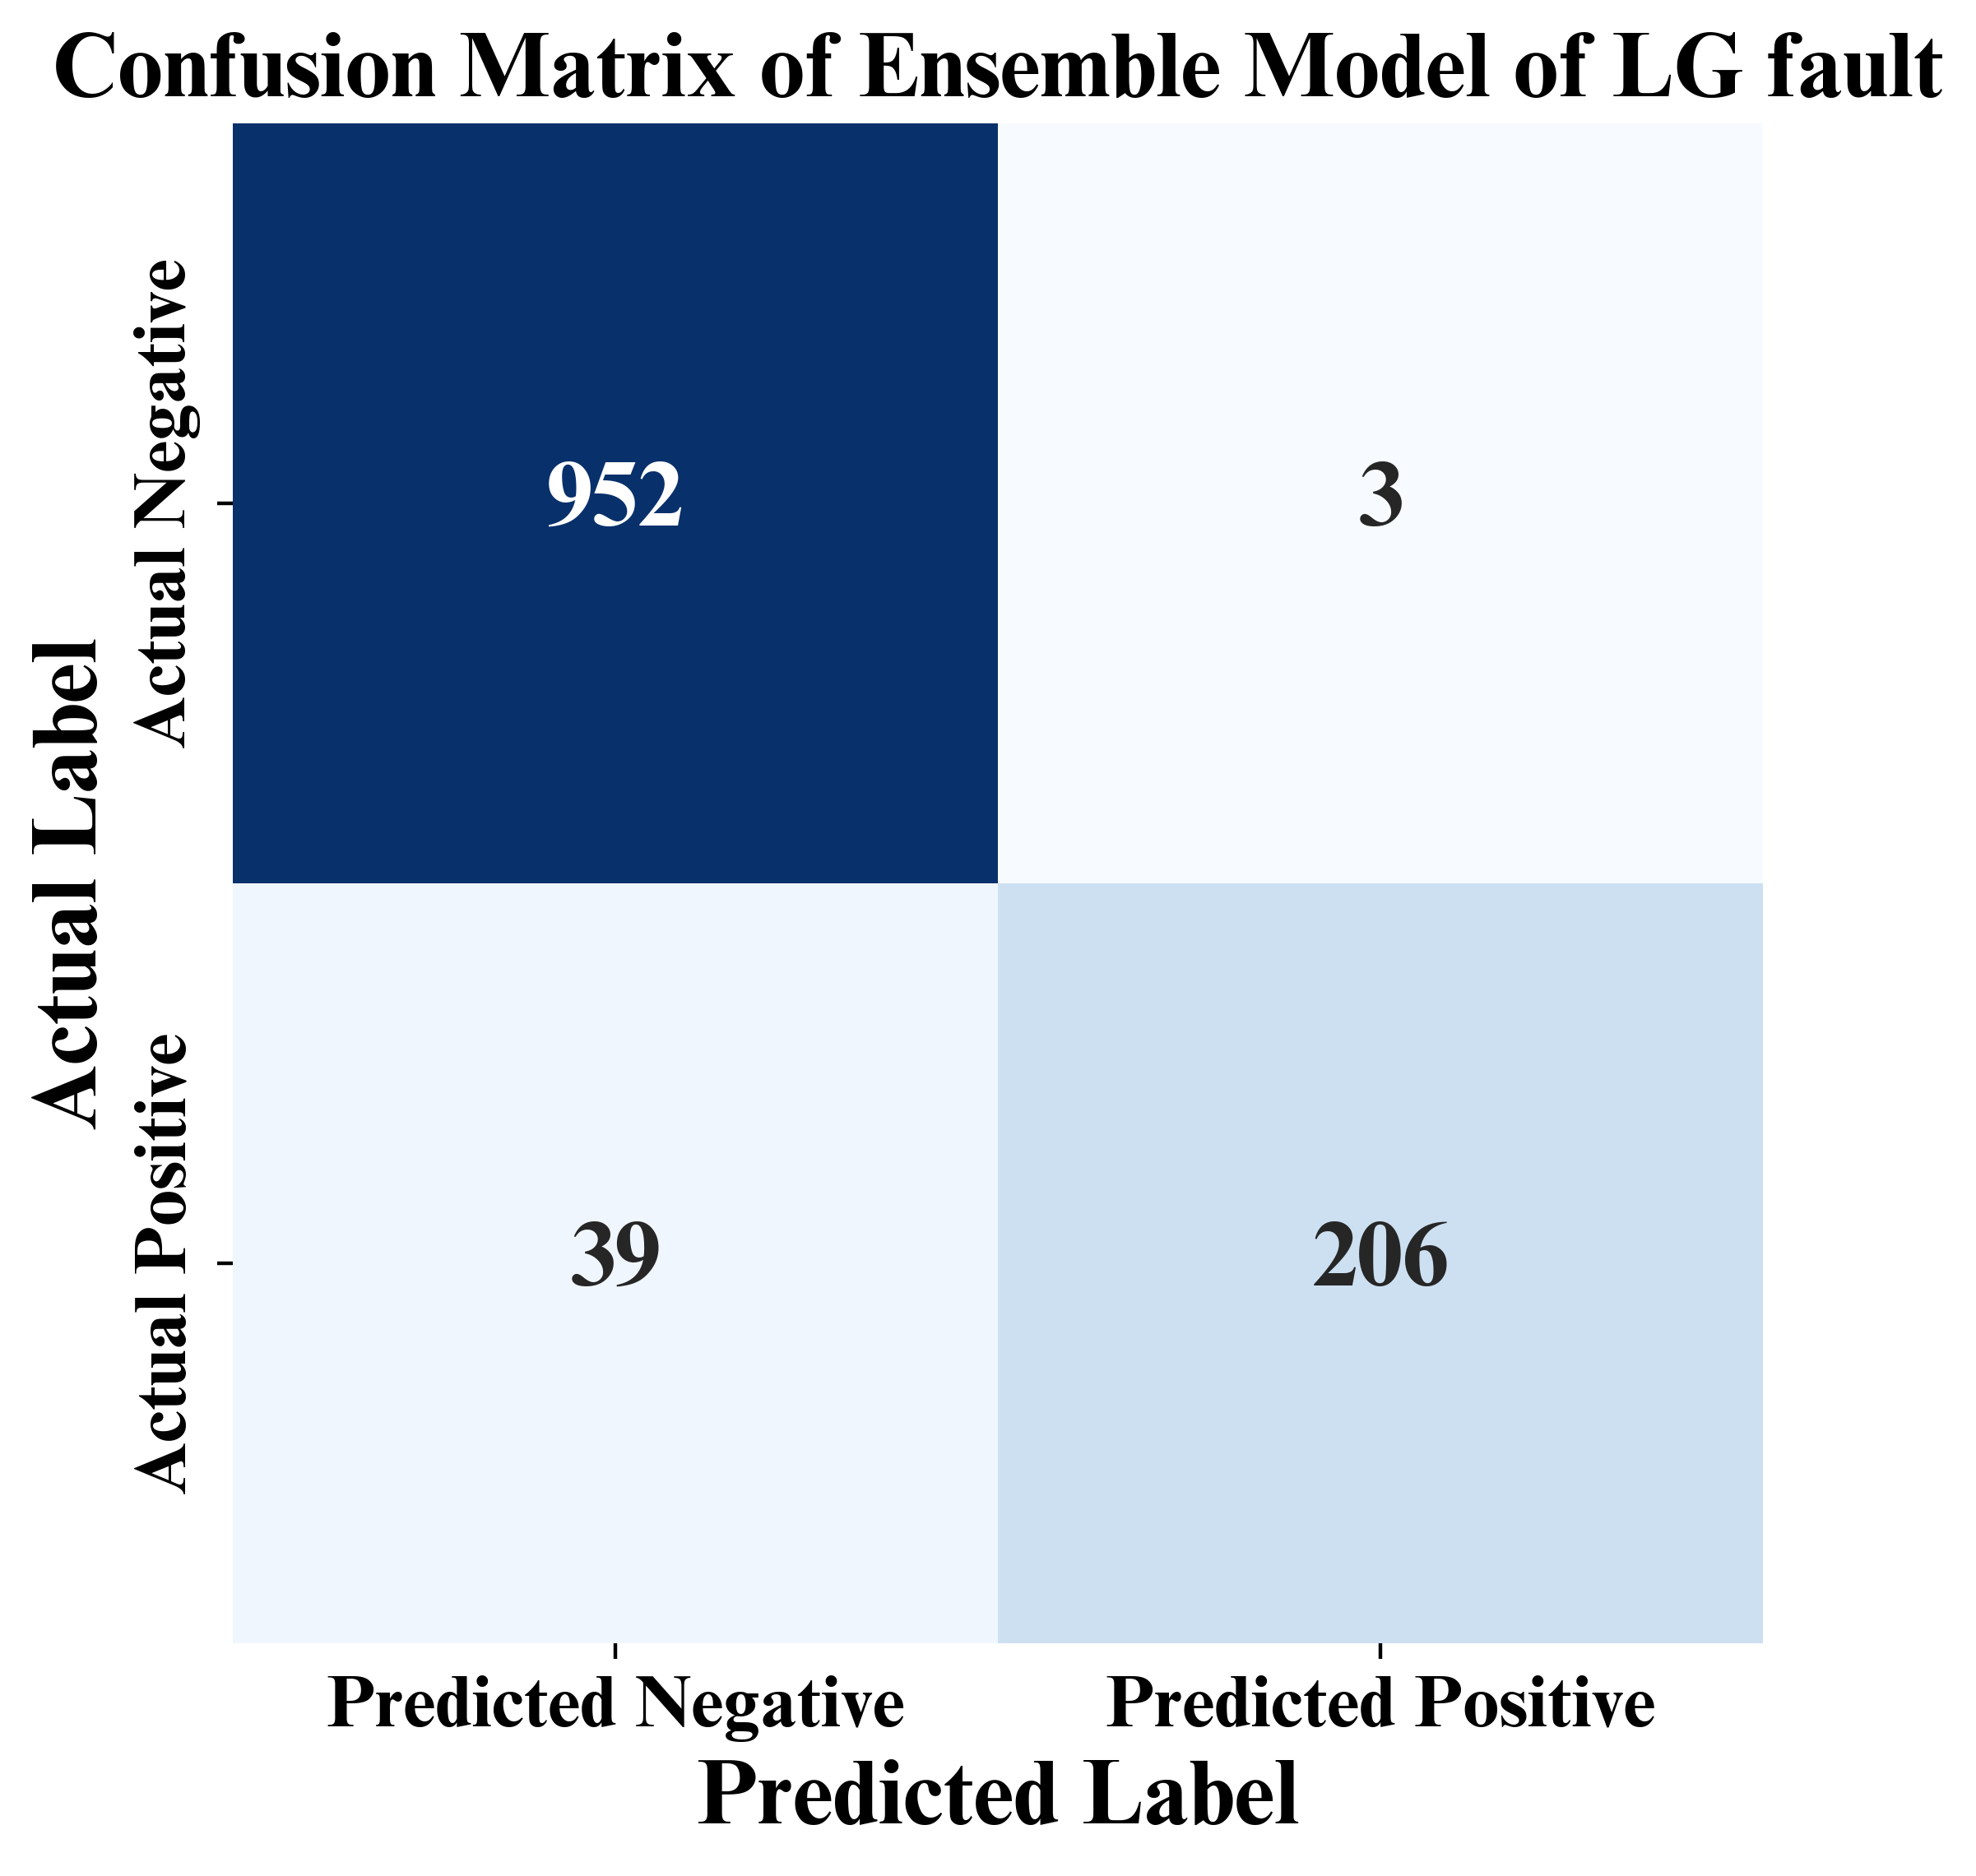

In [ ]:
import seaborn as sns
import matplotlib.pyplot as plt
from matplotlib.font_manager import FontProperties
import numpy as np

font_path = '/content/drive/MyDrive/Fault_dataset/times new roman bold.ttf'
custom_font = FontProperties(fname=font_path)
custom_font.set_size(20)
# Generate the confusion matrix for the ensemble model
ensemble_conf_matrix = np.array([[952, 3], [39, 206]])  # Example data, replace with your confusion matrix

# Plot the heatmap
plt.figure(figsize=(6, 6), dpi=400)
heatmap = sns.heatmap(ensemble_conf_matrix, annot=True, fmt='d', cmap='Blues', cbar=False,
                      xticklabels=['Predicted Negative', 'Predicted Positive'],
                      yticklabels=['Actual Negative', 'Actual Positive'])

# Setting font properties for tick labels
for label in heatmap.get_xticklabels() + heatmap.get_yticklabels():
    label.set_fontproperties(custom_font)

# Set font properties for labels and title
plt.xlabel('Predicted Label', fontproperties=custom_font, fontsize=20)
plt.ylabel('Actual Label', fontproperties=custom_font, fontsize=20)
plt.title('Confusion Matrix of Ensemble Model of LG fault', fontproperties=custom_font, fontsize=20)
plt.xticks(fontproperties=custom_font, fontsize=16)
plt.yticks(fontproperties=custom_font, fontsize=16)
# Set font properties for annotations
for text in heatmap.texts:
    text.set_fontproperties(custom_font)

plt.savefig('plot.png', dpi=400)
plt.show()


## Time prediction

In [ ]:
# 1. Use the stacking model to predict faults on the dataset
stacking_pred = stacking_classifier.predict(X)

# 2. Identify the instances where the stacking model predicts a fault
predicted_fault_indices = np.where(stacking_pred == 1)[0]

# 3. Retrieve the timestamps (time instances) for these predicted fault instances
predicted_fault_times = df.iloc[predicted_fault_indices]['Time']

# Print the predicted fault times
print("Predicted Fault Times:")
print(predicted_fault_times)

Predicted Fault Times:
1055    0.175826
1158    0.192992
1202    0.200325
1203    0.200492
1207    0.201159
          ...   
2397    0.399484
2398    0.399651
2401    0.400151
4058    0.676306
4632    0.771969
Name: Time, Length: 1113, dtype: float64


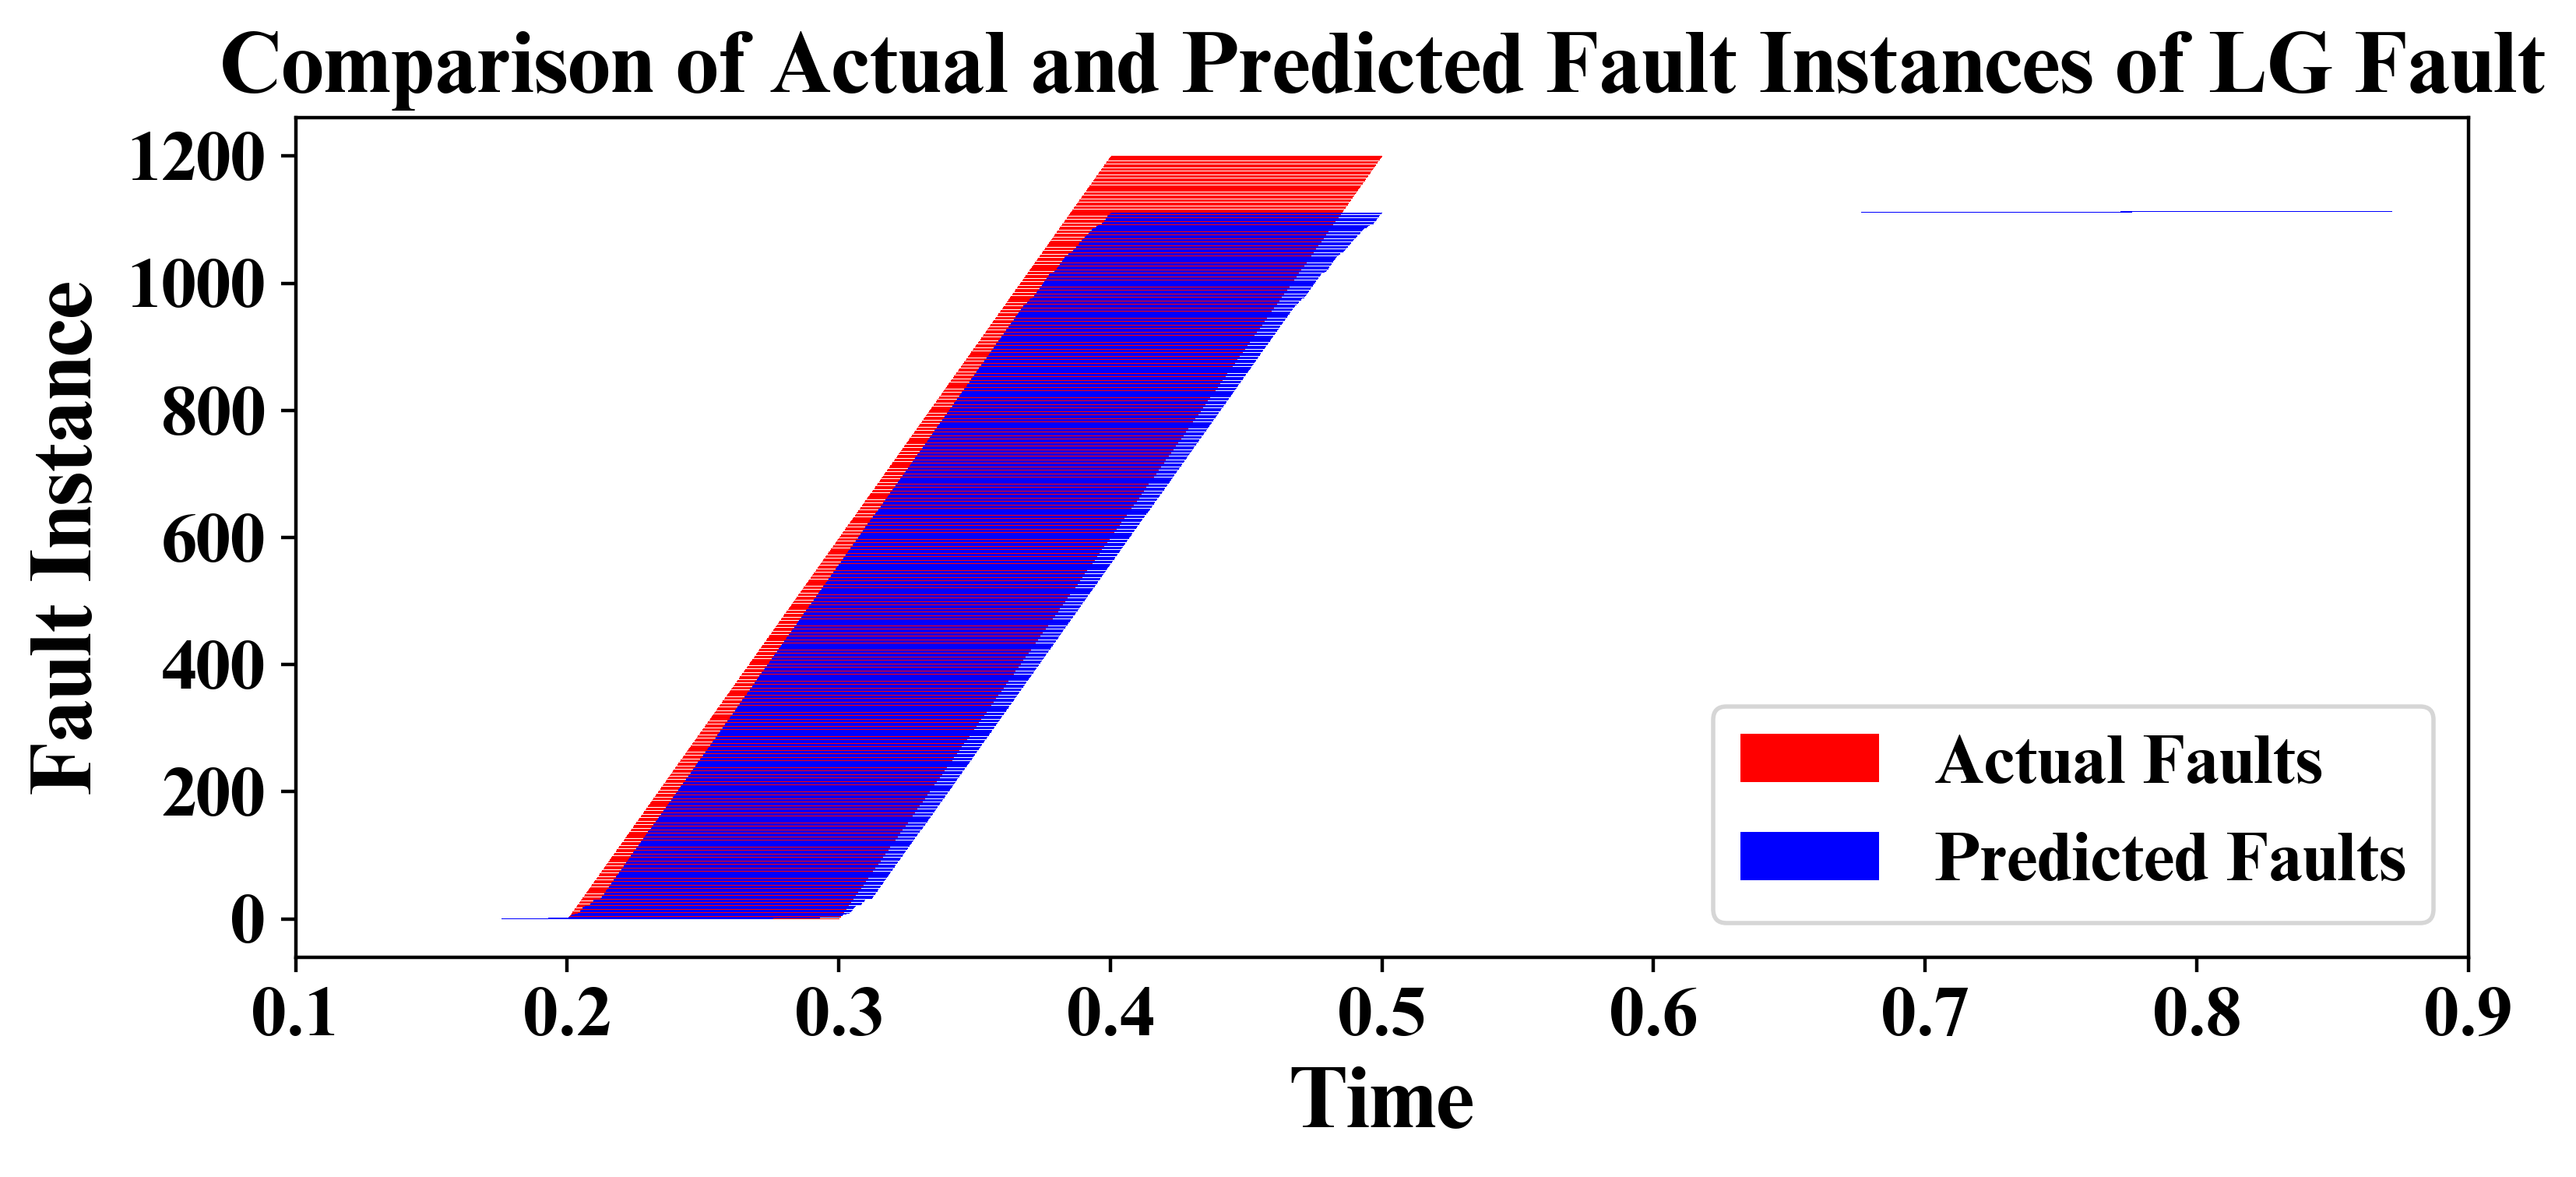

In [ ]:
import matplotlib.pyplot as plt
from matplotlib.font_manager import FontProperties

font_path = '/content/drive/MyDrive/Fault_dataset/times new roman bold.ttf'
custom_font = FontProperties(fname=font_path)
custom_font.set_size(16)

# Extract the time instances of actual faults
actual_fault_times = df[df['Fault'] == 1]['Time']

# Extract the time instances of predicted faults
predicted_fault_times = df.iloc[predicted_fault_indices]['Time']

# Create a timeline-like plot
plt.figure(figsize=(9, 3.5), dpi=400)

# Plot the actual fault instances as red bars
plt.barh(y=range(len(actual_fault_times)), width=0.1, left=actual_fault_times, color='red', label='Actual Faults')

# Plot the predicted fault instances as blue bars
plt.barh(y=[i + 0.5 for i in range(len(predicted_fault_times))], width=0.1, left=predicted_fault_times, color='blue', label='Predicted Faults')
plt.legend(['Actual Faults', 'Predicted Faults'], fontsize=20)
# Add labels and legend with specified font style
plt.xlabel('Time', fontproperties=custom_font, fontsize=20)
plt.ylabel('Fault Instance', fontproperties=custom_font, fontsize=20)
plt.title('Comparison of Actual and Predicted Fault Instances of LG Fault', fontproperties=custom_font, fontsize=20)
plt.legend(prop=custom_font, fontsize=20)

# Set font properties for tick labels
plt.xticks(fontproperties=custom_font, fontsize=16)
plt.yticks(fontproperties=custom_font, fontsize=16)
plt.xlim(0.1, 0.9)
plt.savefig('plot1.png', dpi=400)
plt.show()


In [ ]:
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
import numpy as np
import pandas as pd

# Load your dataset (replace 'your_dataset.csv' with your actual dataset)
df = pd.read_csv('/content/drive/MyDrive/Fault_dataset/AG modified.csv')

# Assuming your features are in columns 0 to n-1, and the target variable (if any) is in column n
X = df.iloc[:, :-1].values  # Features
y = df.iloc[:, -1].values   # Target variable (if any)

# Standardize the features (mean=0 and variance=1)
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

# Initialize PCA with desired number of components
num_components = 3  # Number of principal components to keep
pca = PCA(n_components=num_components)

# Perform PCA on the standardized features
X_pca = pca.fit_transform(X_scaled)

# Explained variance ratio
explained_variance_ratio = pca.explained_variance_ratio_
print("Explained variance ratio:", explained_variance_ratio)

# Cumulative explained variance ratio
cumulative_variance_ratio = np.cumsum(explained_variance_ratio)
print("Cumulative explained variance ratio:", cumulative_variance_ratio)


Explained variance ratio: [0.350277   0.32902559 0.22112527]
Cumulative explained variance ratio: [0.350277   0.67930258 0.90042785]


In [ ]:
import matplotlib.pyplot as plt
from mpl_toolkits.mplot3d import Axes3D  # Importing 3D plot functionality

# Scatter plot of the transformed data
fig = plt.figure(figsize=(10, 8))
ax = fig.add_subplot(111, projection='3d')

# Scatter plot
scatter = ax.scatter(X_pca[:, 0], X_pca[:, 1], X_pca[:, 2], c=y, cmap='viridis')

# Add labels and title
ax.set_xlabel('Principal Component 1', fontproperties=custom_font))
ax.set_ylabel('Principal Component 2', fontproperties=custom_font))
ax.set_zlabel('Principal Component 3', fontproperties=custom_font))
ax.set_title('PCA 3D Scatter Plot')

# Add colorbar
plt.colorbar(scatter, label='Target Variable')

plt.show()


SyntaxError: unmatched ')' (<ipython-input-16-f17475914f65>, line 12)

In [ ]:
import matplotlib.pyplot as plt

# Get the absolute values of the principal components
abs_pca_components = np.abs(pca.components_)

# Plot the absolute values of the principal components
plt.figure(figsize=(10, 6))
num_features = abs_pca_components.shape[1]
bar_width = 0.2
for i in range(num_components):
    plt.bar(np.arange(num_features) + i * bar_width, abs_pca_components[i], width=bar_width, label=f'Principal Component {i+1}')

plt.xlabel('Features')
plt.ylabel('Absolute Values')
plt.title('Absolute Values of PCA Components')
plt.xticks(np.arange(num_features) + bar_width * (num_components - 1) / 2, ['Feature 1', 'Feature 2', 'Feature 3', 'Feature 4'])
plt.legend()
plt.show()


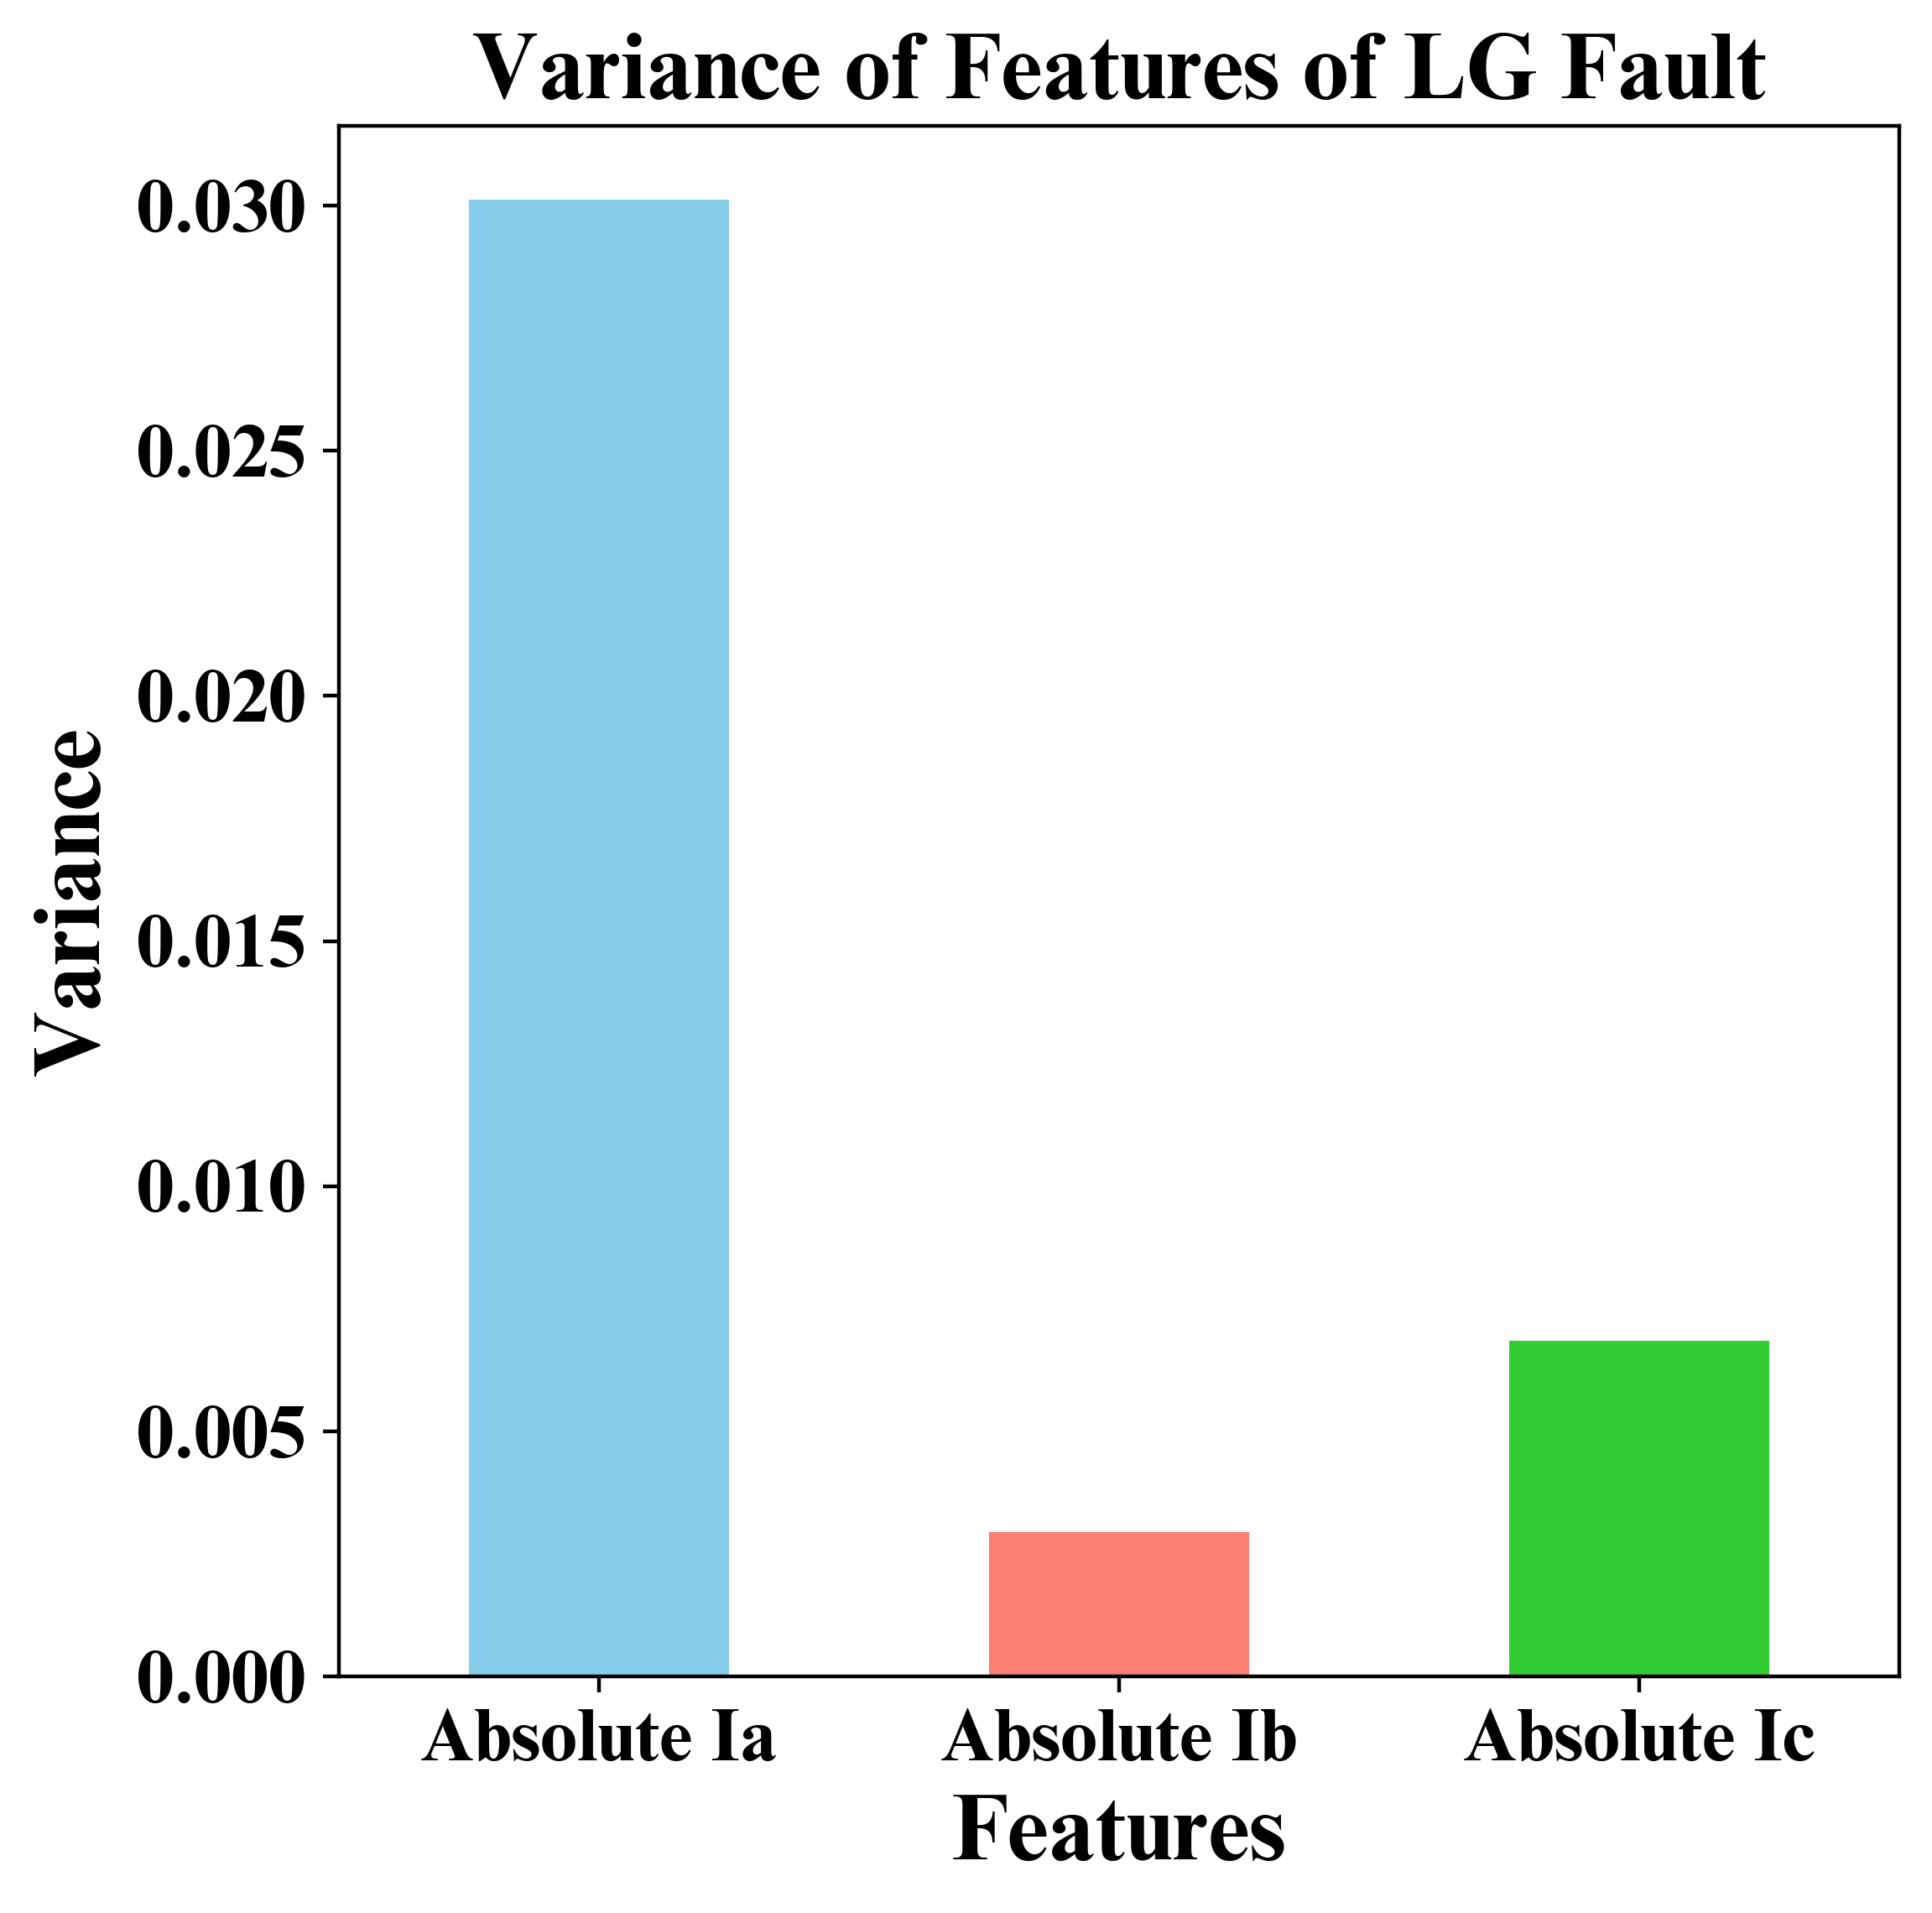

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.font_manager import FontProperties

font_path = '/content/drive/MyDrive/Fault_dataset/times new roman bold.ttf'
custom_font = FontProperties(fname=font_path, size=12)

# Load your dataset (replace 'yoyour_dataset.csvur_dataset.csv' with your actual dataset)
df = pd.read_csv('/content/drive/MyDrive/Fault_dataset/AG modified.csv')

# Select the features of interest
selected_features = ['Absolute Ia', 'Absolute Ib', 'Absolute Ic']

# Calculate the variance of each feature
variances = df[selected_features].var()

# Plot the variances in a bar graph with different colors
plt.figure(figsize=(6, 6), dpi=400)
colors = ['skyblue', 'salmon', 'limegreen']  # Define colors for each feature
variances.plot(kind='bar', color=colors)
plt.xlabel('Features', fontproperties=custom_font, fontsize=20)
plt.ylabel('Variance', fontproperties=custom_font, fontsize=20)
plt.title('Variance of Features of LG Fault', fontproperties=custom_font, fontsize=20)
plt.xticks(rotation=0, fontproperties=custom_font, fontsize=16)
plt.yticks(fontproperties=custom_font, fontsize=16)
plt.savefig('plot1.png', dpi=400)
plt.show()
